# 05. Faster R-CNN: two-stage anchor-based детектор

Друга сім'я детекторів з рубрики. Тренуємо Faster R-CNN (ResNet-50 + FPN, версія v2 з torchvision) з ваг, натренованих на COCO, за тим самим протоколом, що й YOLO:
- train: 56 відео, кожен 5-й кадр (той самий список кадрів, що в `02` і `03`);
- val: 7 відео, усі кадри;
- оцінка: `COCOeval` з оригінальним `annotations_coco.json`, ignored regions як `iscrowd = 1`, ліміт 500 детекцій на кадр, як на Kaggle;
- роздільність: довша сторона кадру 1280 px, як у `03_yolo_1280`, тож ці дві моделі порівнюються напряму.

**Як працює two-stage детектор:**
1. **Backbone + FPN** перетворюють кадр на карти ознак кількох масштабів. Дрібні об'єкти найкраще видно на найдетальнішому рівні (P2, крок 4 px).
2. **RPN (Region Proposal Network), перший етап.** У кожній точці кожної карти стоять заготовлені рамки (anchors) трьох пропорцій. RPN для кожної каже "тут об'єкт чи фон" і трохи її зсуває. Після NMS лишаються ~1000 найкращих пропозицій на кадр, без класу.
3. **RoI head, другий етап.** З кожної пропозиції вирізається шматок карти ознак (RoIAlign, 7×7), і окрема мережа визначає клас (8 + фон) та уточнює рамку.

Розділ 5 окремо міряє, скільки об'єктів знаходить уже перший етап, а скільки втрачається чи виправляється на другому. Це відповідь на питання рубрики, що дає кожен етап.

Налаштування в цьому ноутбуці стандартні (initial). Налаштовувати параметри (розміри anchors під дрібні об'єкти, кількість пропозицій) будемо в наступному запуску, спираючись на розділ 5.

Потрібно: GPU T4 і увімкнений Internet (для `pycocotools` і ваг моделі).

## 0. Налаштування

In [1]:
%pip install -q pycocotools

Note: you may need to restart the kernel to use updated packages.


In [ ]:
import contextlib
import io
import json
import math
import random
import time
from pathlib import Path

import numpy as np
import polars as pl
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import torch
import torchvision
from torch.utils.data import DataLoader, Dataset
from torchvision.io import ImageReadMode, decode_jpeg, read_file
from torchvision.models.detection import FasterRCNN_ResNet50_FPN_V2_Weights, fasterrcnn_resnet50_fpn_v2
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.ops import box_iou
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

SEED = 42
CLASSES = ["person", "bicycle", "car", "van", "truck", "tricycle", "bus", "motor"]

RUN_NAME = "faster_rcnn_r50fpn_v2_1280"
PRETRAINED = True
IMG_SIZE = 1280
EPOCHS = 12 
BATCH = 4
LR = 0.005       
WARMUP_ITERS = 500
STEP = 5              
MAX_TRAIN_HOURS = 6 
WORKERS = 4

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"

print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "немає")

torch 2.11.0+cu128 | torchvision 0.26.0+cu128 | GPU: Tesla T4


Дані шукаємо так само, як у попередніх ноутбуках. Усі результати пишемо в `/kaggle/working`.

In [3]:
ROOT = next(
    path.parent
    for pattern in ["*/test_images.csv", "*/*/test_images.csv", "*/*/*/test_images.csv"]
    for path in Path("/kaggle/input").glob(pattern)
)
OUT = Path("/kaggle/working")
CKPT_DIR = OUT / "checkpoints"
CKPT_DIR.mkdir(exist_ok=True)
print(ROOT)

/kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026


## 1. Дані

Faster R-CNN з torchvision приймає рамки у форматі `[x1, y1, x2, y2]` у пікселях і мітки класів, де 0 зарезервовано під фон. Тому беремо рамки з `annotations_coco.json`: там вони вже в пікселях, а `category_id` від 1 до 8 якраз збігається з потрібною нумерацією.

Що відкидаємо:
- ignored regions (`iscrowd = 1`): це не об'єкти, вони потрібні лише для оцінки;
- вироджені рамки з шириною чи висотою менше 1 px: на них torchvision падає з помилкою.

Список кадрів train будуємо тим самим кодом, що в YOLO, тож модель бачить ті самі кадри.

In [ ]:
def frame_list(split):
    return pl.DataFrame({"path": sorted(str(path) for path in (ROOT / split / "images").rglob("*.jpg"))}).with_columns(
        video=pl.col("path").str.split("/").list.get(-2)
    )


def frame_key(path):
    return "/".join(Path(path).parts[-2:])


def load_split(split):
    coco = json.loads((ROOT / split / "annotations_coco.json").read_text())
    key_by_id = {image["id"]: frame_key(image["file_name"]) for image in coco["images"]}
    boxes = {key: [] for key in key_by_id.values()}
    skipped = 0
    for ann in coco["annotations"]:
        if ann.get("iscrowd", 0):
            continue
        x, y, w, h = ann["bbox"]
        if w < 1 or h < 1:
            skipped += 1
            continue
        boxes[key_by_id[ann["image_id"]]].append((x, y, x + w, y + h, ann["category_id"]))
    return coco, boxes, skipped


train_frames = frame_list("train").filter((pl.int_range(pl.len()).over("video") % STEP) == 0)
val_frames = frame_list("val")

_, train_boxes, train_skipped = load_split("train")
val_coco, val_boxes, _ = load_split("val")

train_paths = train_frames["path"].to_list()
print("train:", len(train_paths), "кадрів з", train_frames["video"].n_unique(), "відео;", sum(len(train_boxes[frame_key(p)]) for p in train_paths), "рамок; відкинуто вироджених:", train_skipped)
print("val:", val_frames.height, "кадрів з", val_frames["video"].n_unique(), "відео")

train: 4868 кадрів з 56 відео; 222879 рамок; відкинуто вироджених: 0
val: 2846 кадрів з 7 відео


Датасет повертає кадр як тензор з байтами 0–255 (так його вчетверо дешевше передавати між процесами), а в числа від 0 до 1 він переводиться вже на GPU. Масштабування до 1280 і нормалізацію модель робить сама всередині, і потім так само сама повертає рамки в пікселі оригінального кадру.

Аугментація на train лише одна: віддзеркалення по горизонталі з імовірністю 0.5. Це стандарт для Faster R-CNN. YOLO за замовчуванням використовує набагато сильніші аугментації (mosaic, зміну кольорів, масштабу). Цю різницю протоколів варто згадати у звіті при порівнянні.

In [ ]:
def read_image(path):
    return decode_jpeg(read_file(str(path)), mode=ImageReadMode.RGB)


class DetectionDataset(Dataset):
    def __init__(self, paths, boxes=None, train=False):
        self.paths = paths
        self.boxes = boxes
        self.train = train

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        path = self.paths[index]
        image = read_image(path)
        if self.boxes is None:
            return image, path
        items = self.boxes[frame_key(path)]
        boxes = torch.tensor([item[:4] for item in items], dtype=torch.float32).reshape(-1, 4)
        labels = torch.tensor([item[4] for item in items], dtype=torch.int64)
        if self.train and random.random() < 0.5:
            width = image.shape[-1]
            image = image.flip(-1)
            boxes = torch.stack([width - boxes[:, 2], boxes[:, 1], width - boxes[:, 0], boxes[:, 3]], dim=1)
        return image, {"boxes": boxes, "labels": labels}


def collate(batch):
    return tuple(zip(*batch))


def to_device(images):
    return [image.to(DEVICE, non_blocking=True).float() / 255 for image in images]


def seed_worker(worker_id):
    random.seed(SEED + worker_id)
    np.random.seed(SEED + worker_id)


train_loader = DataLoader(
    DetectionDataset(train_paths, train_boxes, train=True),
    batch_size=BATCH,
    shuffle=True,
    num_workers=WORKERS,
    collate_fn=collate,
    worker_init_fn=seed_worker,
    generator=torch.Generator().manual_seed(SEED),
    drop_last=True,
    pin_memory=DEVICE.type == "cuda",
    persistent_workers=WORKERS > 0,
)
print(len(train_loader), "кроків на епоху")

1217 кроків на епоху


## 2. Модель

Беремо Faster R-CNN v2 з torchvision з вагами COCO і замінюємо останній шар класифікатора: замість 91 класу COCO в нас 8 класів + фон. Решта мережі стартує з навчених ваг.

Що змінено відносно налаштувань torchvision за замовчуванням, і чому:
- `min_size = max_size = 1280`: довша сторона кадру 1280 px, як у `03_yolo_1280` (за замовчуванням ~1333 × 800);
- `box_detections_per_img = 500`: ліміт Kaggle (за замовчуванням 100, а в нас буває до 180 об'єктів на кадрі);
- `box_score_thresh = 0.001`: низький поріг для оцінки mAP, як `conf=0.001` у YOLO.

Anchors і RPN поки стандартні: розміри 32, 64, 128, 256, 512 px (по одному на рівень FPN) і пропорції 0.5, 1, 2. Найменший anchor, 32 px, більший за типовий об'єкт у нас (10–30 px). Наскільки це шкодить, покаже розділ 5.

In [6]:
def build_model(pretrained):
    model = fasterrcnn_resnet50_fpn_v2(
        weights=FasterRCNN_ResNet50_FPN_V2_Weights.DEFAULT if pretrained else None,
        weights_backbone=None,
        min_size=IMG_SIZE,
        max_size=IMG_SIZE,
        box_detections_per_img=500,
        box_score_thresh=0.001,
    )
    in_features = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, len(CLASSES) + 1)
    return model


model = build_model(PRETRAINED).to(DEVICE)
print("anchors:", model.rpn.anchor_generator.sizes, "| пропорції:", model.rpn.anchor_generator.aspect_ratios[0])
print("параметрів:", round(sum(p.numel() for p in model.parameters()) / 1e6, 1), "млн")

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth


100%|██████████| 167M/167M [00:01<00:00, 152MB/s]


anchors: ((32,), (64,), (128,), (256,), (512,)) | пропорції: (0.5, 1.0, 2.0)
параметрів: 43.3 млн


## 3. Тренування

Оптимізатор і розклад як у референсних скриптах torchvision: SGD з momentum 0.9 і weight decay 1e-4, на початку 500 кроків warmup (learning rate плавно росте від майже нуля), потім косинусне згасання до кінця. Learning rate 0.005: у torchvision 0.02 при batch 16, ділимо пропорційно на batch 4. Для стабільності ще обрізаємо норму градієнта до 10 і пропускаємо батчі з нескінченним loss.

**BatchNorm.** У версії v2 backbone і FPN містять звичайні шари BatchNorm, які під час тренування оновлюють свої статистики (середнє і дисперсію) по батчу. При batch 4 ці оцінки дуже шумні й псують навчені на COCO ваги, тому статистики backbone і FPN заморожуємо. Ваги цих шарів при цьому навчаються як звичайно.

Mixed precision (AMP) пришвидшує тренування на T4 приблизно вдвічі. Передбачення (і швидка оцінка після кожної епохи) йдуть у повній точності, пояснення в розділі 4.

Після кожної епохи рахуємо mAP на швидкій підвибірці val (кожен 5-й кадр). Так видно криву навчання по епохах, яку рубрика просить порівняти з DETR, і зберігаємо ваги найкращої епохи. Повна оцінка на всіх кадрах val буде в розділі 4.

**Бюджет часу `MAX_TRAIN_HOURS`.** Після першої епохи ноутбук міряє, скільки вона тривала. Якщо 12 епох не вміщаються в бюджет, кількість епох зменшується одразу, і косинусний розклад перебудовується під нову кількість. Так learning rate встигає плавно згаснути до кінця, а не обривається на середині. Друга лінія захисту: якщо епохи все одно затягнуться, тренування зупиниться раніше, і ноутбук піде далі до оцінки та сабміту з найкращими вагами. Сесія точно не впреться в 12-годинний ліміт Kaggle.

In [ ]:
def predict(model, paths, batch_size=BATCH):
    loader = DataLoader(DetectionDataset(paths), batch_size=batch_size, num_workers=WORKERS, collate_fn=collate, pin_memory=DEVICE.type == "cuda")
    model.eval()
    results, total_time, timed_images = {}, 0.0, 0
    with torch.no_grad():
        for batch_index, (images, batch_paths) in enumerate(loader):
            images = to_device(images)
            if DEVICE.type == "cuda":
                torch.cuda.synchronize()
            start = time.perf_counter()
            outputs = model(images)
            if DEVICE.type == "cuda":
                torch.cuda.synchronize()
            if batch_index > 0:
                total_time += time.perf_counter() - start
                timed_images += len(images)
            for path, output in zip(batch_paths, outputs):
                results[frame_key(path)] = (output["boxes"].float().cpu(), output["scores"].float().cpu(), output["labels"].cpu())
    return results, 1000 * total_time / max(timed_images, 1)


val_id_by_key = {frame_key(image["file_name"]): image["id"] for image in val_coco["images"]}


def to_coco_detections(results):
    return [
        {"image_id": val_id_by_key[key], "category_id": int(label), "bbox": [round(float(x1), 2), round(float(y1), 2), round(float(x2 - x1), 2), round(float(y2 - y1), 2)], "score": round(float(score), 4)}
        for key, (boxes, scores, labels) in results.items()
        for (x1, y1, x2, y2), score, label in zip(boxes.tolist(), scores.tolist(), labels.tolist())
    ]


ground_truth = COCO(str(ROOT / "val" / "annotations_coco.json"))


def coco_evaluate(detections, image_ids=None, verbose=False):
    if not detections:
        return None, {"mAP": 0.0, "AP50": 0.0}
    sink = io.StringIO()
    with contextlib.redirect_stdout(sink):
        evaluator = COCOeval(ground_truth, ground_truth.loadRes(detections), "bbox")
        evaluator.params.maxDets = [1, 100, 500]
        if image_ids is not None:
            evaluator.params.imgIds = image_ids
        evaluator.evaluate()
        evaluator.accumulate()
        evaluator.summarize()
    if verbose:
        print(sink.getvalue())
    precision = evaluator.eval["precision"][:, :, :, 0, 2]
    return evaluator, {
        "mAP": float(np.mean(precision[precision > -1])) if (precision > -1).any() else 0.0,
        "AP50": float(evaluator.stats[1]),
    }


quick_val_paths = val_frames.filter((pl.int_range(pl.len()).over("video") % 5) == 0)["path"].to_list()
quick_val_ids = [val_id_by_key[frame_key(p)] for p in quick_val_paths]
print("швидка підвибірка val:", len(quick_val_paths), "кадрів")

loading annotations into memory...
Done (t=0.39s)
creating index...
index created!
швидка підвибірка val: 571 кадрів


In [ ]:
params = [p for p in model.parameters() if p.requires_grad]
optimizer = torch.optim.SGD(params, lr=LR, momentum=0.9, weight_decay=1e-4)
total_iters = EPOCHS * len(train_loader)


def lr_factor(step):
    if step < WARMUP_ITERS:
        return 0.001 + (1 - 0.001) * step / WARMUP_ITERS
    progress = (step - WARMUP_ITERS) / max(total_iters - WARMUP_ITERS, 1)
    return 0.01 + 0.99 * 0.5 * (1 + math.cos(math.pi * min(progress, 1.0)))


scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_factor)


def freeze_backbone_bn(model):
    for module in model.backbone.modules():
        if isinstance(module, torch.nn.BatchNorm2d):
            module.eval()
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

history = []
best_map = -1.0
skipped_batches = 0
start = time.time()

for epoch in range(1, EPOCHS + 1):
    if epoch > EPOCHS:
        break
    epoch_start = time.time()
    model.train()
    freeze_backbone_bn(model)
    sums = {}
    steps = 0
    for images, targets in train_loader:
        images = to_device(images)
        targets = [{k: v.to(DEVICE, non_blocking=True) for k, v in t.items()} for t in targets]
        with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
            loss_dict = model(images, targets)
            loss = sum(loss_dict.values())
        if not torch.isfinite(loss):
            skipped_batches += 1
            optimizer.zero_grad(set_to_none=True)
            scheduler.step()
            continue
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(params, 10.0)
        scaler.step(optimizer)
        scaler.update()
        optimizer.zero_grad(set_to_none=True)
        scheduler.step()
        for name, value in loss_dict.items():
            sums[name] = sums.get(name, 0.0) + value.item()
        steps += 1

    results, _ = predict(model, quick_val_paths)
    _, quick = coco_evaluate(to_coco_detections(results), quick_val_ids)
    row = {
        "epoch": epoch,
        **{f"train/{name}": round(total / max(steps, 1), 4) for name, total in sums.items()},
        "val_mAP": round(quick["mAP"], 4),
        "val_AP50": round(quick["AP50"], 4),
        "lr": optimizer.param_groups[0]["lr"],
        "minutes": round((time.time() - epoch_start) / 60, 1),
    }
    history.append(row)
    torch.save(model.state_dict(), CKPT_DIR / "last.pt")
    if quick["mAP"] > best_map:
        best_map = quick["mAP"]
        torch.save(model.state_dict(), CKPT_DIR / "best.pt")
    pl.DataFrame(history).write_csv(OUT / f"history_{RUN_NAME}.csv")

    elapsed_hours = (time.time() - start) / 3600
    if epoch == 1:
        fit = max(int(MAX_TRAIN_HOURS / elapsed_hours), 2)
        if fit < EPOCHS:
            EPOCHS = fit
            total_iters = EPOCHS * len(train_loader)
            print(f"епоха триває {elapsed_hours * 60:.0f} хв: скорочую розклад до {EPOCHS} епох, щоб вкластись у {MAX_TRAIN_HOURS} год")
    print(f"епоха {epoch}/{EPOCHS} | {row['minutes']} хв | loss {sum(v for k, v in row.items() if k.startswith('train/')):.3f} | quick mAP {row['val_mAP']:.4f} | AP50 {row['val_AP50']:.4f}")
    if epoch < EPOCHS and elapsed_hours + elapsed_hours / epoch > MAX_TRAIN_HOURS + 0.5:
        print(f"зупиняю після епохи {epoch}: наступна не вкладеться в {MAX_TRAIN_HOURS} год")
        break

train_hours = (time.time() - start) / 3600
epochs_done = len(history)
print(f"тренування: {train_hours:.2f} год, епох: {epochs_done}, пропущено батчів: {skipped_batches}, найкращий quick mAP: {best_map:.4f}")

епоха 1/12 | 17.1 хв | loss 0.982 | quick mAP 0.2076 | AP50 0.4448
епоха 2/12 | 17.0 хв | loss 0.719 | quick mAP 0.2323 | AP50 0.4704
епоха 3/12 | 17.0 хв | loss 0.650 | quick mAP 0.2268 | AP50 0.4576
епоха 4/12 | 16.9 хв | loss 0.603 | quick mAP 0.2416 | AP50 0.4774
епоха 5/12 | 16.9 хв | loss 0.565 | quick mAP 0.2460 | AP50 0.4838
епоха 6/12 | 16.8 хв | loss 0.532 | quick mAP 0.2411 | AP50 0.4705
епоха 7/12 | 16.8 хв | loss 0.501 | quick mAP 0.2350 | AP50 0.4594
епоха 8/12 | 16.8 хв | loss 0.477 | quick mAP 0.2343 | AP50 0.4529
епоха 9/12 | 16.7 хв | loss 0.454 | quick mAP 0.2292 | AP50 0.4437
епоха 10/12 | 16.7 хв | loss 0.439 | quick mAP 0.2298 | AP50 0.4447
епоха 11/12 | 16.7 хв | loss 0.427 | quick mAP 0.2287 | AP50 0.4404
епоха 12/12 | 16.7 хв | loss 0.420 | quick mAP 0.2266 | AP50 0.4381
тренування: 3.37 год, епох: 12, пропущено батчів: 0, найкращий quick mAP: 0.2460


Криві навчання: чотири складові loss (дві від RPN і дві від RoI head) і mAP на швидкій підвибірці val по епохах. Файл `history_faster_rcnn_r50fpn_v2_1280.csv` знадобиться для спільного графіка з RT-DETR.

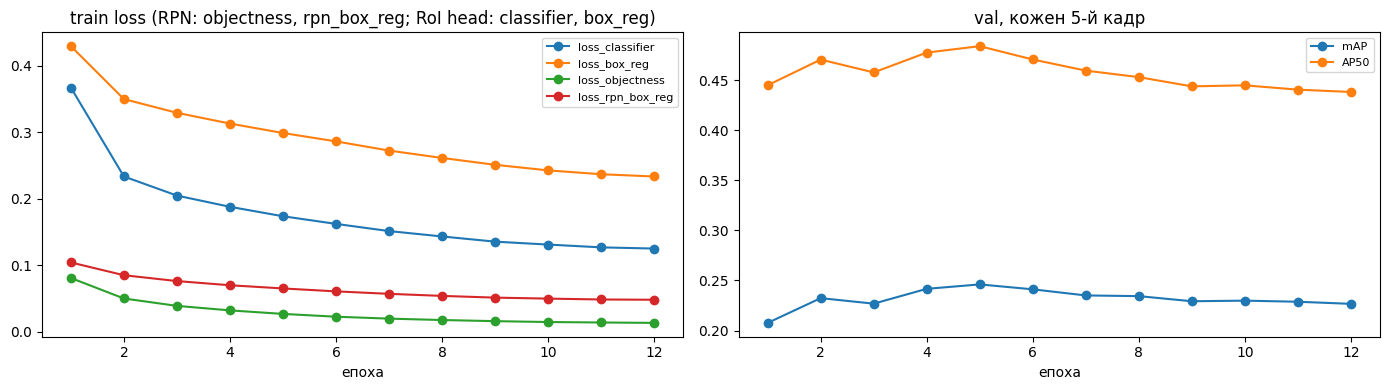

epoch,train/loss_classifier,train/loss_box_reg,train/loss_objectness,train/loss_rpn_box_reg,val_mAP,val_AP50,lr,minutes
i64,f64,f64,f64,f64,f64,f64,f64,f64
1,0.3673,0.4296,0.0809,0.1043,0.2076,0.4448,0.004969,17.1
2,0.2336,0.35,0.0501,0.0851,0.2323,0.4704,0.004774,17.0
3,0.2049,0.3294,0.039,0.0763,0.2268,0.4576,0.004415,17.0
4,0.188,0.3132,0.0322,0.07,0.2416,0.4774,0.003918,16.9
5,0.1738,0.299,0.0269,0.0652,0.246,0.4838,0.003319,16.9
…,…,…,…,…,…,…,…,…
8,0.1434,0.2615,0.0177,0.054,0.2343,0.4529,0.001368,16.8
9,0.1356,0.2512,0.016,0.0514,0.2292,0.4437,0.000824,16.7
10,0.1312,0.2428,0.0147,0.0499,0.2298,0.4447,0.000405,16.7


In [9]:
history_df = pl.DataFrame(history)
loss_names = [name for name in history_df.columns if name.startswith("train/")]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for name in loss_names:
    axes[0].plot(history_df["epoch"], history_df[name], marker="o", label=name.replace("train/", ""))
axes[0].set_title("train loss (RPN: objectness, rpn_box_reg; RoI head: classifier, box_reg)")
axes[1].plot(history_df["epoch"], history_df["val_mAP"], marker="o", label="mAP")
axes[1].plot(history_df["epoch"], history_df["val_AP50"], marker="o", label="AP50")
axes[1].set_title("val, кожен 5-й кадр")
for ax in axes:
    ax.set_xlabel("епоха")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
history_df

## 4. Оцінка на всіх кадрах val

Беремо ваги найкращої епохи і передбачаємо всі кадри val. Рахуємо ті самі метрики, що й для YOLO. Швидкість тут: час одного проходу моделі разом з масштабуванням кадру і NMS, поділений на кількість кадрів (batch 4, T4, fp32, перший батч не рахуємо). При порівнянні з YOLO у звіті варто вказати ці умови.

Чесна примітка для звіту: найкращу епоху ми обираємо за швидкою підвибіркою val, яка є частиною того самого val. Це невелике завищення оцінки, але воно однакове для всіх наших моделей.

Передбачаємо в повній точності (fp32), а не в mixed precision: під AMP torchvision рахує координати рамок у 16-бітних числах, і похибка доходить до ~1 px. Для об'єктів розміром 10–30 px це помітно знижує mAP на суворих порогах IoU. Тренування при цьому лишається з AMP, як у референсних скриптах torchvision.

In [10]:
model.load_state_dict(torch.load(CKPT_DIR / "best.pt", map_location=DEVICE))
val_results, ms_per_image = predict(model, val_frames["path"].to_list())
detections = to_coco_detections(val_results)
(OUT / f"val_predictions_{RUN_NAME}.json").write_text(json.dumps(detections))
evaluator, main = coco_evaluate(detections, verbose=True)
print(len(detections), "детекцій на", len(val_results), "кадрах;", f"{ms_per_image:.1f} ms/кадр")

Loading and preparing results...
DONE (t=2.38s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=118.80s).
Accumulating evaluation results...
DONE (t=9.38s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.242
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=500 ] = 0.480
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=500 ] = 0.213
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=500 ] = 0.099
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=500 ] = 0.224
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=500 ] = 0.423
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.141
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.460
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=500 ] = 0.460
 Average Recall     (AR) @[ IoU=0.50:0.95 | area= small | maxDets=

Головні цифри одним рядком у файл `result_*.json`, як у кожному ноутбуці. `mAP` тут з лімітом 500 детекцій (так рахує Kaggle). `mAP_maxdet100` — перший рядок таблиці вище, для порівняння зі старим значенням бейзлайну YOLO.

In [11]:
stats = evaluator.stats
result_row = {
    "run": RUN_NAME,
    "model": "fasterrcnn_resnet50_fpn_v2 (COCO)",
    "imgsz": IMG_SIZE,
    "epochs": epochs_done,
    "train_frames": len(train_paths),
    "mAP": round(main["mAP"], 4),
    "mAP_maxdet100": round(stats[0], 4),
    "AP50": round(stats[1], 4),
    "AP75": round(stats[2], 4),
    "AP_small": round(stats[3], 4),
    "AP_medium": round(stats[4], 4),
    "AP_large": round(stats[5], 4),
    "AR500": round(stats[8], 4),
    "ms_per_image": round(ms_per_image, 1),
    "train_hours": round(train_hours, 2),
}
(OUT / f"result_{RUN_NAME}.json").write_text(json.dumps(result_row, indent=2))
pl.DataFrame([result_row])

run,model,imgsz,epochs,train_frames,mAP,mAP_maxdet100,AP50,AP75,AP_small,AP_medium,AP_large,AR500,ms_per_image,train_hours
str,str,i64,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""faster_rcnn_r50fpn_v2_1280""","""fasterrcnn_resnet50_fpn_v2 (CO…",1280,12,4868,0.2416,0.2416,0.4799,0.2135,0.0994,0.2236,0.4226,0.4596,198.3,3.37


AP по класах (з лімітом 500), щоб побачити класи, які модель майже не знаходить.

In [12]:
precision = evaluator.eval["precision"][:, :, :, 0, 2]
pl.DataFrame(
    [
        {
            "class": name,
            "AP": round(float(np.mean(precision[:, :, i][precision[:, :, i] > -1])), 4) if (precision[:, :, i] > -1).any() else None,
            "AP50": round(float(np.mean(precision[0, :, i][precision[0, :, i] > -1])), 4) if (precision[0, :, i] > -1).any() else None,
        }
        for i, name in enumerate(CLASSES)
    ]
)

class,AP,AP50
str,f64,f64
"""person""",0.279,0.6556
"""bicycle""",0.2591,0.5729
"""car""",0.3725,0.6126
"""van""",0.2518,0.4638
"""truck""",0.3236,0.5546
"""tricycle""",0.2594,0.5452
"""bus""",0.0609,0.0775
"""motor""",0.1267,0.3572


## 5. Що дає кожен етап: recall пропозицій RPN проти фінальних детекцій

Беремо швидку підвибірку val і для кожного справжнього об'єкта перевіряємо:
- **RPN recall**: чи є серед ~1000 пропозицій першого етапу хоч одна, що перекриває об'єкт з IoU ≥ 0.5 (і ≥ 0.7);
- **фінальний recall**: чи є серед фінальних детекцій другого етапу рамка з IoU ≥ 0.5 (без урахування класу і з усіма детекціями, до 500 на кадр).

Як читати: якщо RPN recall для дрібних об'єктів низький, другий етап їх уже не врятує, бо він працює лише з пропозиціями. Тоді проблема в anchors і RPN (кандидат для налаштування). Якщо RPN recall високий, а фінальний значно нижчий, втрати на другому етапі (класифікація, NMS у щільних сценах). Розміри як у COCO: small < 32², medium до 96², large більше.

In [13]:
@torch.no_grad()
def rpn_proposals(model, paths):
    model.eval()
    loader = DataLoader(DetectionDataset(paths), batch_size=BATCH, num_workers=WORKERS, collate_fn=collate)
    proposals = {}
    for images, batch_paths in loader:
        images = to_device(images)
        original_sizes = [image.shape[-2:] for image in images]
        image_list, _ = model.transform(images)
        features = model.backbone(image_list.tensors)
        boxes, _ = model.rpn(image_list, features)
        for path, box, (h, w), (oh, ow) in zip(batch_paths, boxes, image_list.image_sizes, original_sizes):
            scale = torch.tensor([ow / w, oh / h, ow / w, oh / h], device=box.device)
            proposals[frame_key(path)] = (box.float() * scale).cpu()
    return proposals


def best_iou(gt, candidates):
    if len(gt) == 0:
        return torch.zeros(0)
    if len(candidates) == 0:
        return torch.zeros(len(gt))
    return box_iou(gt, candidates).max(dim=1).values


proposals = rpn_proposals(model, quick_val_paths)
records = []
for path in quick_val_paths:
    key = frame_key(path)
    gt = torch.tensor([item[:4] for item in val_boxes[key]], dtype=torch.float32).reshape(-1, 4)
    if len(gt) == 0:
        continue
    area = (gt[:, 2] - gt[:, 0]) * (gt[:, 3] - gt[:, 1])
    rpn_iou = best_iou(gt, proposals[key])
    final_iou = best_iou(gt, val_results[key][0])
    records += [
        {"size": "small" if a < 32**2 else "medium" if a < 96**2 else "large", "rpn_iou": float(r), "final_iou": float(f)}
        for a, r, f in zip(area.tolist(), rpn_iou.tolist(), final_iou.tolist())
    ]

recall_table = (
    pl.DataFrame(records)
    .group_by("size")
    .agg(
        objects=pl.len(),
        rpn_recall_50=(pl.col("rpn_iou") >= 0.5).mean().round(3),
        rpn_recall_70=(pl.col("rpn_iou") >= 0.7).mean().round(3),
        final_recall_50=(pl.col("final_iou") >= 0.5).mean().round(3),
    )
    .sort(pl.col("size").replace_strict({"small": 0, "medium": 1, "large": 2}))
)
print("пропозицій RPN на кадр:", round(float(np.mean([len(p) for p in proposals.values()])), 1))
recall_table.write_csv(OUT / f"rpn_recall_{RUN_NAME}.csv")
recall_table

пропозицій RPN на кадр: 1000.0


size,objects,rpn_recall_50,rpn_recall_70,final_recall_50
str,u32,f64,f64,f64
"""small""",4393,0.629,0.356,0.597
"""medium""",15917,0.801,0.603,0.775
"""large""",2596,0.988,0.961,0.982


## 6. Три приклади помилок

Для кожного кадру val порівнюємо впевнені детекції (score ≥ 0.3) зі справжніми рамками при IoU ≥ 0.5 і рахуємо три типи помилок:
- **пропущені дрібні об'єкти**: справжній об'єкт < 32² без жодної детекції поруч;
- **хибні спрацювання**: детекція, якої немає серед справжніх об'єктів і яка не лежить в ignored region;
- **плутанина класів**: рамка на правильному місці, але клас неправильний.

Для кожного типу показуємо кадр, де таких помилок найбільше. Позначення: зелена рамка — знайдений об'єкт, жовта — пропущений, червона — хибне спрацювання, фіолетова — неправильний клас, сіра заливка — ignored region.

Ці три кадри та їхній опис потрібні для звіту: варто пояснити, чому модель помиляється саме так (розмір об'єкта, щільність, перекриття, схожі класи на кшталт `car`/`van` чи `bicycle`/`motor`).

In [14]:
SCORE_THR = 0.3

ignored_by_id = {}
for ann in val_coco["annotations"]:
    if ann.get("iscrowd", 0):
        x, y, w, h = ann["bbox"]
        ignored_by_id.setdefault(ann["image_id"], []).append((x, y, x + w, y + h))


def analyse_frame(key):
    gt_items = val_boxes[key]
    gt = torch.tensor([item[:4] for item in gt_items], dtype=torch.float32).reshape(-1, 4)
    gt_labels = torch.tensor([item[4] for item in gt_items], dtype=torch.int64)
    boxes, scores, labels = val_results[key]
    keep = scores >= SCORE_THR
    boxes, labels = boxes[keep], labels[keep]
    ignored = torch.tensor(ignored_by_id.get(val_id_by_key[key], []), dtype=torch.float32).reshape(-1, 4)

    iou = box_iou(gt, boxes) if len(gt) and len(boxes) else torch.zeros(len(gt), len(boxes))
    gt_hit = iou.max(dim=1).values >= 0.5 if len(boxes) else torch.zeros(len(gt), dtype=torch.bool)
    gt_best = iou.argmax(dim=1) if len(boxes) else torch.zeros(len(gt), dtype=torch.int64)
    wrong_class = gt_hit & (labels[gt_best] != gt_labels) if len(boxes) else torch.zeros(len(gt), dtype=torch.bool)
    det_hit = iou.max(dim=0).values >= 0.5 if len(gt) else torch.zeros(len(boxes), dtype=torch.bool)

    in_ignored = torch.zeros(len(boxes), dtype=torch.bool)
    if len(ignored) and len(boxes):
        lt = torch.max(boxes[:, None, :2], ignored[None, :, :2])
        rb = torch.min(boxes[:, None, 2:], ignored[None, :, 2:])
        inter = (rb - lt).clamp(min=0).prod(dim=2)
        det_area = ((boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1])).clamp(min=1)
        in_ignored = (inter / det_area[:, None]).max(dim=1).values >= 0.5
    false_pos = ~det_hit & ~in_ignored

    area = (gt[:, 2] - gt[:, 0]) * (gt[:, 3] - gt[:, 1])
    return {
        "key": key,
        "gt": gt, "gt_hit": gt_hit, "wrong_class": wrong_class,
        "dets": boxes, "false_pos": false_pos, "ignored": ignored,
        "missed_small": int((~gt_hit & (area < 32**2)).sum()),
        "false_positives": int(false_pos.sum()),
        "class_confusions": int(wrong_class.sum()),
        "objects": len(gt),
    }


frames = [analyse_frame(key) for key in val_results]
summary = pl.DataFrame([{k: f[k] for k in ["key", "objects", "missed_small", "false_positives", "class_confusions"]} for f in frames])
print("усього на val:", summary.select("objects", "missed_small", "false_positives", "class_confusions").sum().to_dicts()[0])

chosen = []
for column in ["missed_small", "false_positives", "class_confusions"]:
    for row in summary.sort(column, descending=True).iter_rows(named=True):
        if row["key"] not in [c[1] for c in chosen]:
            chosen.append((column, row["key"]))
            break
summary.filter(pl.col("key").is_in([key for _, key in chosen]))

усього на val: {'objects': 114132, 'missed_small': 10721, 'false_positives': 24033, 'class_confusions': 10052}


key,objects,missed_small,false_positives,class_confusions
str,i64,i64,i64,i64
"""uav0000117_02622_v/0000303.jpg""",93,21,3,5
"""uav0000137_00458_v/0000204.jpg""",107,2,15,22
"""uav0000182_00000_v/0000225.jpg""",66,14,42,11


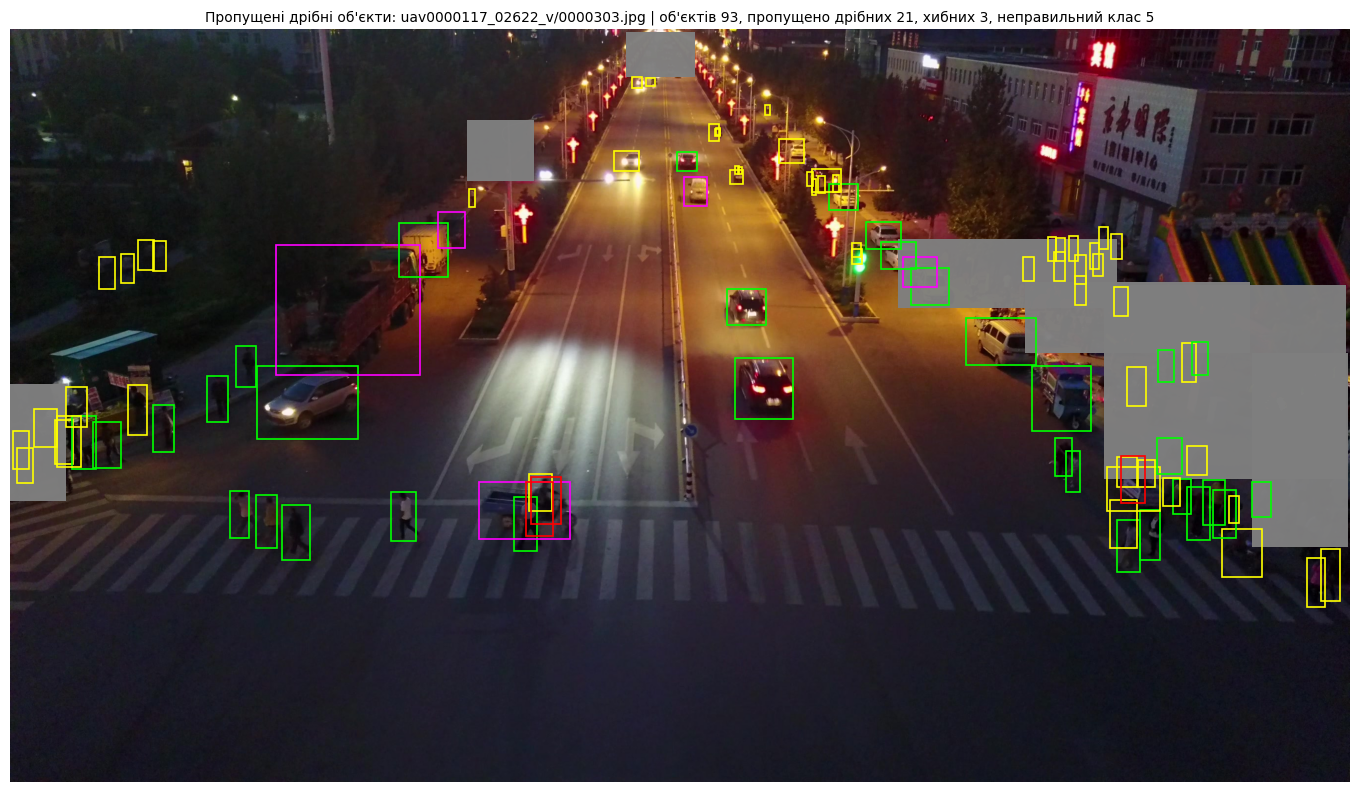

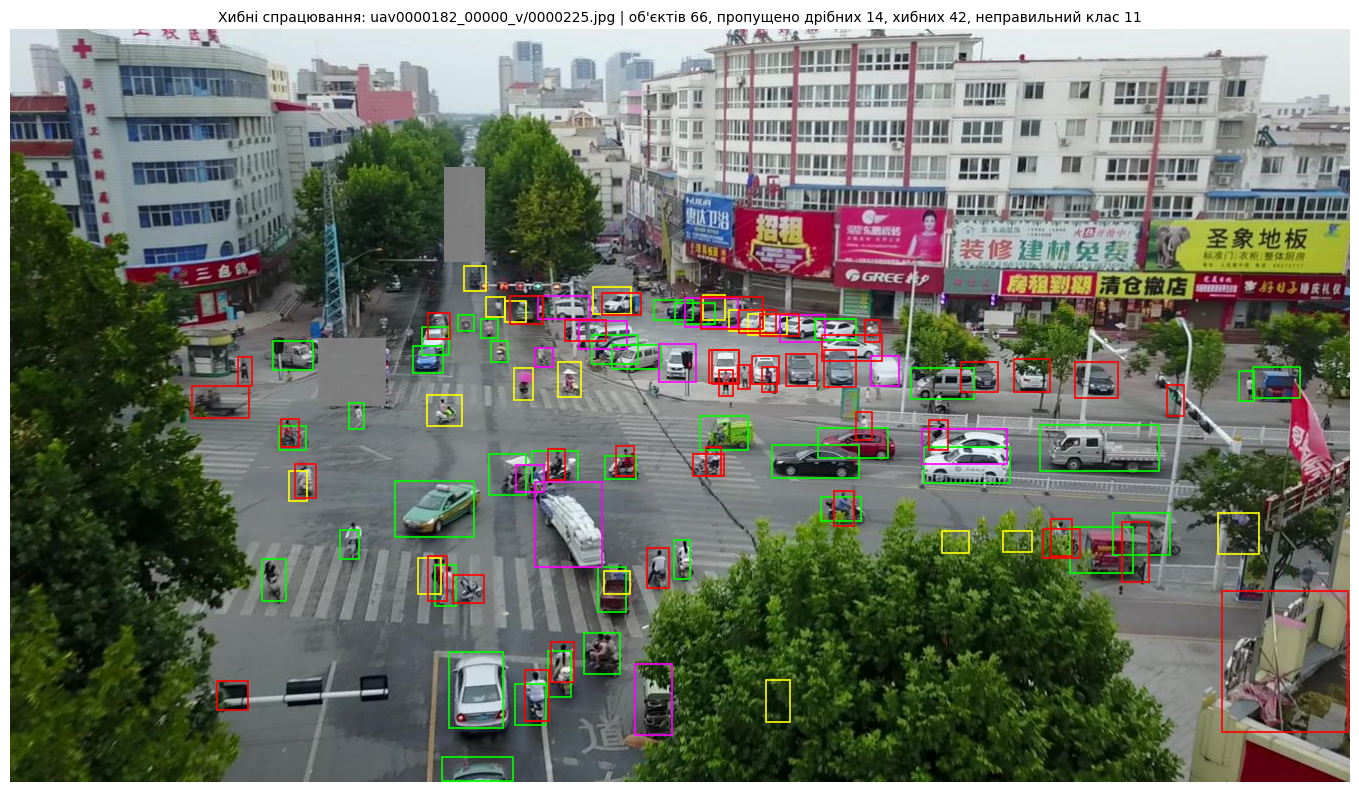

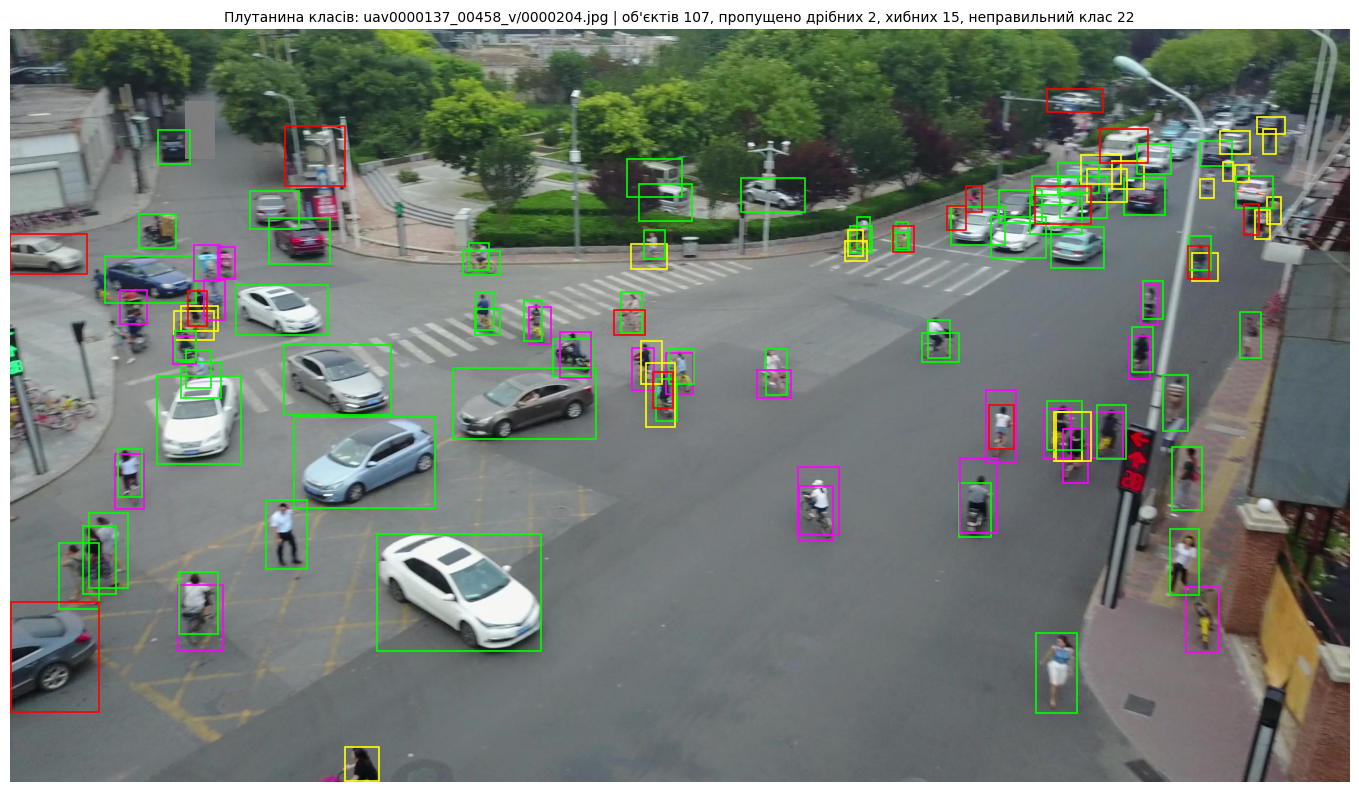

In [15]:
def draw_case(title, frame):
    image = read_image(val_frames.filter(pl.col("path").str.ends_with(frame["key"]))["path"][0]).permute(1, 2, 0).numpy()
    fig, ax = plt.subplots(figsize=(14, 8))
    ax.imshow(image)
    for x1, y1, x2, y2 in frame["ignored"].tolist():
        ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, facecolor="gray", alpha=0.35, edgecolor="none"))
    for (x1, y1, x2, y2), hit, wrong in zip(frame["gt"].tolist(), frame["gt_hit"].tolist(), frame["wrong_class"].tolist()):
        color = "magenta" if wrong else "lime" if hit else "yellow"
        ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=color, linewidth=1.2))
    for (x1, y1, x2, y2), fp in zip(frame["dets"].tolist(), frame["false_pos"].tolist()):
        if fp:
            ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor="red", linewidth=1.2))
    ax.set_title(f"{title}: {frame['key']} | об'єктів {frame['objects']}, пропущено дрібних {frame['missed_small']}, хибних {frame['false_positives']}, неправильний клас {frame['class_confusions']}", fontsize=10)
    ax.axis("off")
    plt.tight_layout()
    plt.show()


titles = {"missed_small": "Пропущені дрібні об'єкти", "false_positives": "Хибні спрацювання", "class_confusions": "Плутанина класів"}
frames_by_key = {f["key"]: f for f in frames}
for column, key in chosen:
    draw_case(titles[column], frames_by_key[key])

## 7. Сабміт на Kaggle

Передбачаємо всі кадри test тими самими вагами. torchvision повертає рамки вже в пікселях оригінального кадру. Лишається перевести мітки 1–8 у класи 0–7 і кути рамки в ширину й висоту. Кадри без детекцій лишаються з порожнім рядком.

In [ ]:
test_images = pl.read_csv(ROOT / "test_images.csv")
test_results, _ = predict(model, [str(ROOT / file_name) for file_name in test_images["file_name"]])

predictions = {
    image_id: " ".join(
        f"{label - 1} {score:.4f} {x1:.2f} {y1:.2f} {x2 - x1:.2f} {y2 - y1:.2f}"
        for (x1, y1, x2, y2), score, label in zip(*[t.tolist() for t in test_results[frame_key(file_name)]])
        if x2 - x1 >= 0.5 and y2 - y1 >= 0.5
    )
    for image_id, file_name in test_images.select("image_id", "file_name").iter_rows()
}

submission = test_images.select("image_id").with_columns(
    PredictionString=pl.col("image_id").replace_strict(predictions, default="")
)
submission.write_csv(OUT / "submission.csv")
submission.write_csv(OUT / f"submission_{RUN_NAME}.csv")
print(submission.height, "рядків,", (submission["PredictionString"] == "").sum(), "порожніх")
submission.head()

3811 рядків, 0 порожніх


image_id,PredictionString
str,str
"""clip_001_0000001""","""0 0.9951 724.78 890.71 62.27 1…"
"""clip_001_0000002""","""0 0.9954 1659.98 790.87 63.69 …"
"""clip_001_0000003""","""0 0.9932 771.75 897.83 64.88 1…"
"""clip_001_0000004""","""0 0.9944 759.51 904.54 65.95 1…"
"""clip_001_0000005""","""0 0.9945 730.20 914.92 68.44 1…"


Перевірка формату перед відправкою, та сама, що в YOLO.

In [17]:
rows = (
    submission.join(test_images.select("image_id", "width", "height"), on="image_id")
    .filter(pl.col("PredictionString") != "")
    .with_columns(values=pl.col("PredictionString").str.split(" ").cast(pl.List(pl.Float64)))
)
boxes = rows.select(
    "width",
    "height",
    *[pl.col("values").list.gather_every(6, offset).alias(name) for offset, name in enumerate(["cls", "score", "x", "y", "w", "h"])],
).explode("cls", "score", "x", "y", "w", "h")

{
    "рядків як у test_images.csv": submission.height == test_images.height,
    "кількість чисел кратна 6": rows.select((pl.col("values").list.len() % 6 == 0).all()).item(),
    "не більше 500 рамок на кадр": rows.select((pl.col("values").list.len() <= 6 * 500).all()).item(),
    "класи від 0 до 7": boxes["cls"].is_between(0, 7).all(),
    "score від 0 до 1": boxes["score"].is_between(0, 1).all(),
    "ширина і висота більші за 0": bool((boxes["w"] > 0).all() and (boxes["h"] > 0).all()),
    "рамки в межах кадру": boxes.select(
        ((pl.col("x") >= -1) & (pl.col("y") >= -1) & (pl.col("x") + pl.col("w") <= pl.col("width") + 1) & (pl.col("y") + pl.col("h") <= pl.col("height") + 1)).all()
    ).item(),
}

{'рядків як у test_images.csv': True,
 'кількість чисел кратна 6': True,
 'не більше 500 рамок на кадр': True,
 'класи від 0 до 7': True,
 'score від 0 до 1': True,
 'ширина і висота більші за 0': True,
 'рамки в межах кадру': True}